In [1]:
import pandas as pd 
import numpy as np 
from collections import Counter
import matplotlib as mpl 
import matplotlib.pyplot as plt
import pickle 
import statistics
from scipy import stats
import cv2

In [439]:
key = '/Multiplex 6/MP3-058-2'

In [440]:
registration_base_path = 'Y:/coskun-lab/Aditi/01/Results/registration' + key + '/1x'

In [441]:
cell_clustering_base_path = 'Y:/coskun-lab/Aditi/01/Results/cell_segmentation_clustering' + key + '/1x'

In [442]:
cell_cluster_loc_df = pd.read_csv(cell_clustering_base_path + '/cell_cluster_location_merged_unclassified_within_contour.csv').drop(columns=['Unnamed: 0'])
with open(cell_clustering_base_path + '/segmentation_mask_merged_within_contour_for_pixel_clustering.pickle', 'rb') as f: 
    cell_segmentation_mask = pickle.load(f)
with open(cell_clustering_base_path + '/cell_type_color_dict.pickle', 'rb') as f: 
    cell_type_color_dict = pickle.load(f)

In [443]:
with open(registration_base_path + '/roi_coord_dict.pickle', 'rb') as f: 
    roi = pickle.load(f)

#### Visualize Cell Distribution 

In [444]:
def view_clustered_cells_merged(cell_location_expression_cluster_type_df, cell_type_color_dict, merged_segmentation_mask_matrix, img_h, img_w, circle=True, background=None):

    if(background == None):
        img = np.full((img_h, img_w, 3), (0, 0, 0))

    if(circle == True):
        for cell_type, group in cell_location_expression_cluster_type_df.groupby('Cell Type'):
            r, g, b = cell_type_color_dict[cell_type]
            color = (int(r * 255), int(g * 255), int(b * 255))
            pts = group[['X', 'Y']].to_numpy(dtype=np.int32)
            for x, y in pts:
                cv2.circle(img, (x, y), 10, color, -1, lineType=cv2.LINE_AA)
    else:
        labels = merged_segmentation_mask_matrix

        for cell_type, (r, g, b) in cell_type_color_dict.items():
            color = np.array(
                [int(r * 255), int(g * 255), int(b * 255)],
                dtype=np.uint8
            )

            cell_idx = (
                cell_location_expression_cluster_type_df
                .loc[cell_location_expression_cluster_type_df['Cell Type'] == cell_type, 'index']
                .astype(int)
                .values
            )

            lookup = np.zeros(labels.max() + 1, dtype=bool)
            lookup[cell_idx] = True

            mask = lookup[labels]
            img[mask] = color


    return img
 

In [445]:
cell_type_overlay_matrix = view_clustered_cells_merged(cell_cluster_loc_df, cell_type_color_dict, cell_segmentation_mask, cell_segmentation_mask.shape[0], cell_segmentation_mask.shape[1], True)

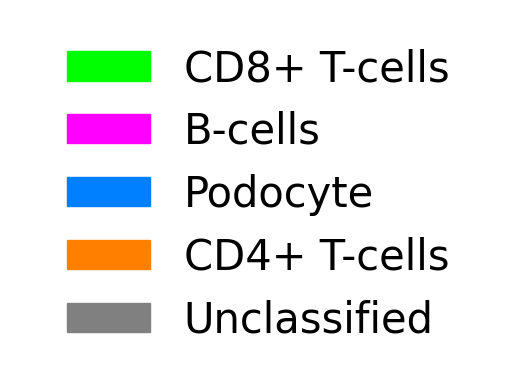

In [446]:
import matplotlib.patches as mpatches
fig, ax = plt.subplots(1)

i = 0
patches = [
    mpatches.Patch(color=color, label=label)
    for label, color in zip(list(cell_type_color_dict.keys()), list(cell_type_color_dict.values()))]
ax.legend(patches, list(cell_type_color_dict.keys()), loc='center', frameon=False, ncol=1) #=int(len(list(cell_type_color_dict.keys()))))
ax.axis('off')
i+=1
plt.show()

In [447]:
selected_roi = list(roi.keys())

A
B
C


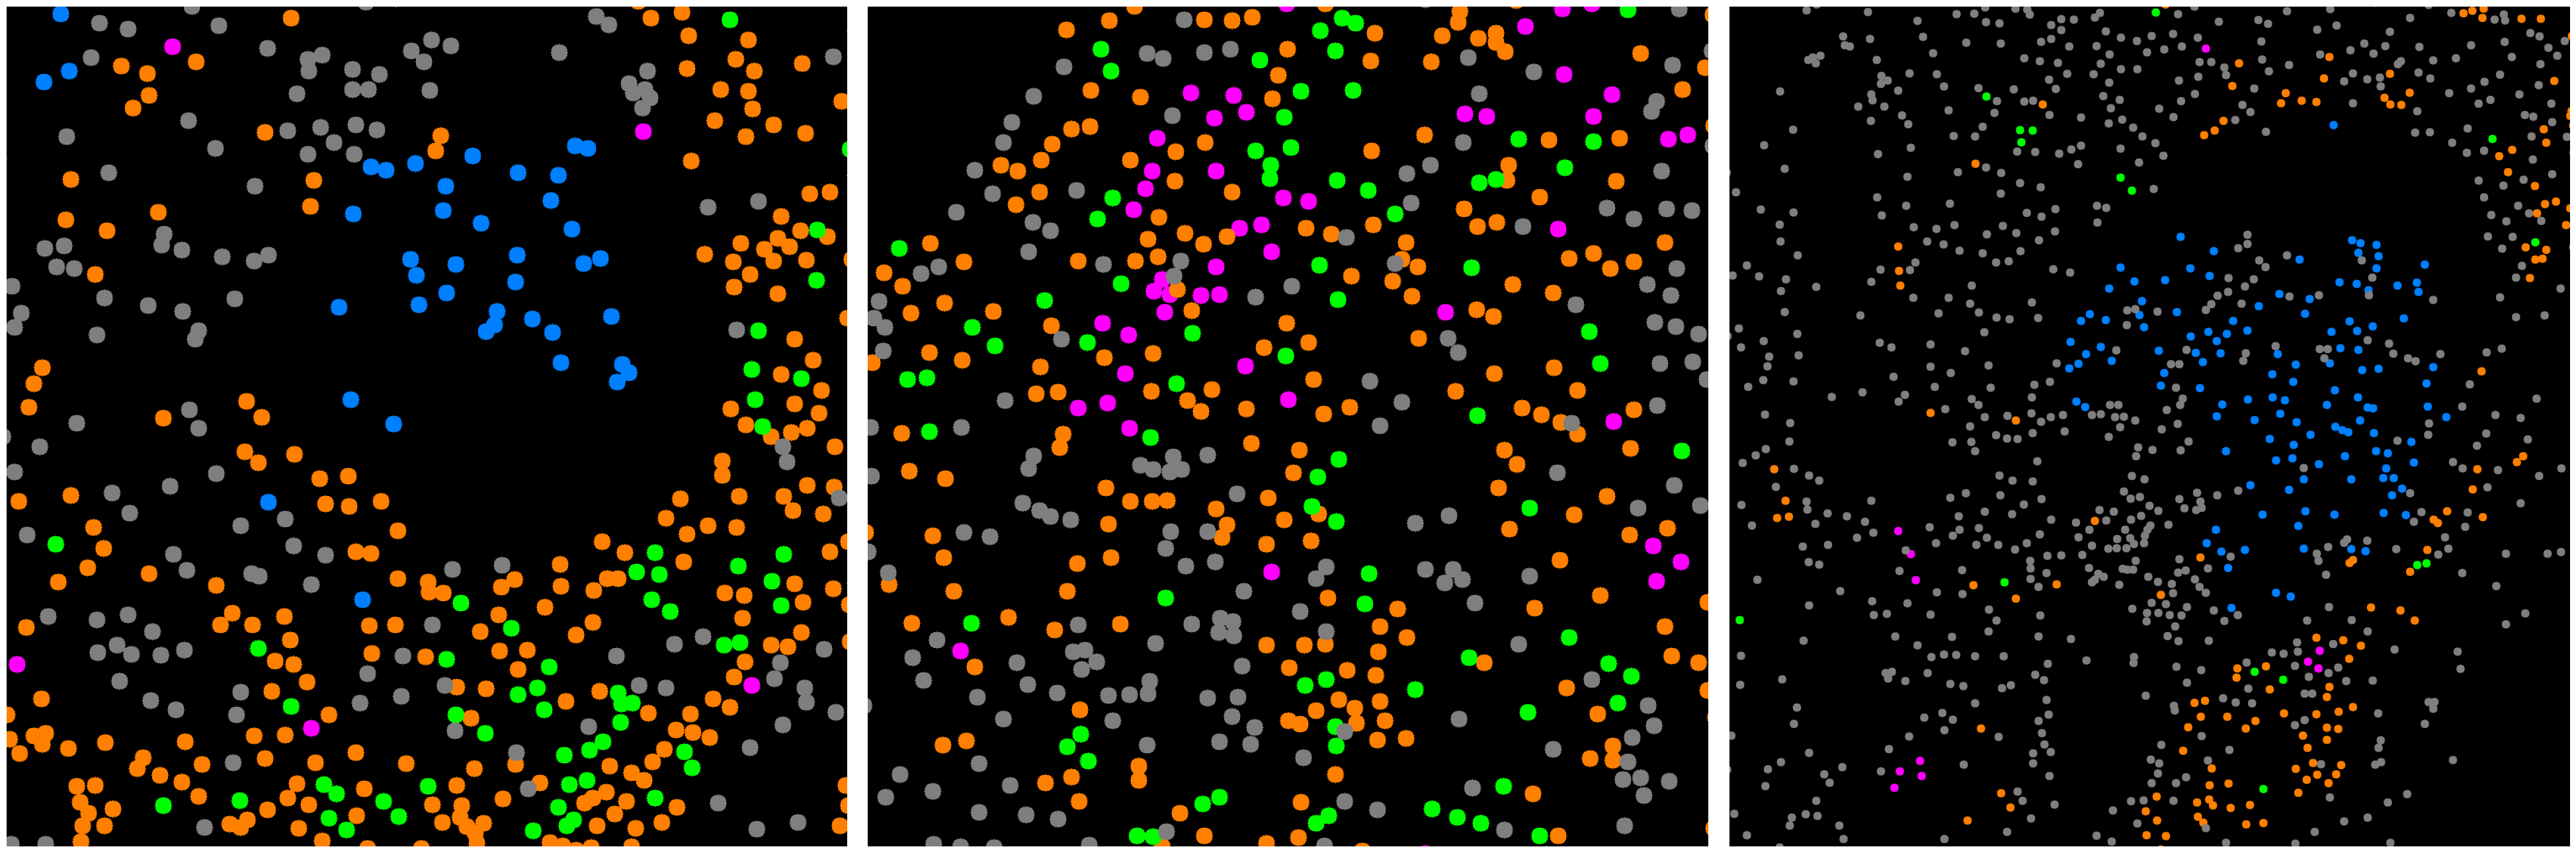

In [448]:
fig, ax = plt.subplots(1, len(selected_roi))
fig.set_figheight(30)
fig.set_figwidth(50)
i = 0
for name, coord in roi.items():
    if(name not in selected_roi):
        continue
    print(name)
    img_labeled = cell_type_overlay_matrix[coord[0]:coord[1], coord[2]:coord[3]]
    ax[i].imshow(img_labeled.astype(np.uint8))
    ax[i].axis('off')
    i+=1 

plt.subplots_adjust(wspace=0.025, hspace=0.025)


#### Quantify Cell Count and Fraction per Tile

In [449]:
cell_types = list(cell_type_color_dict.keys())

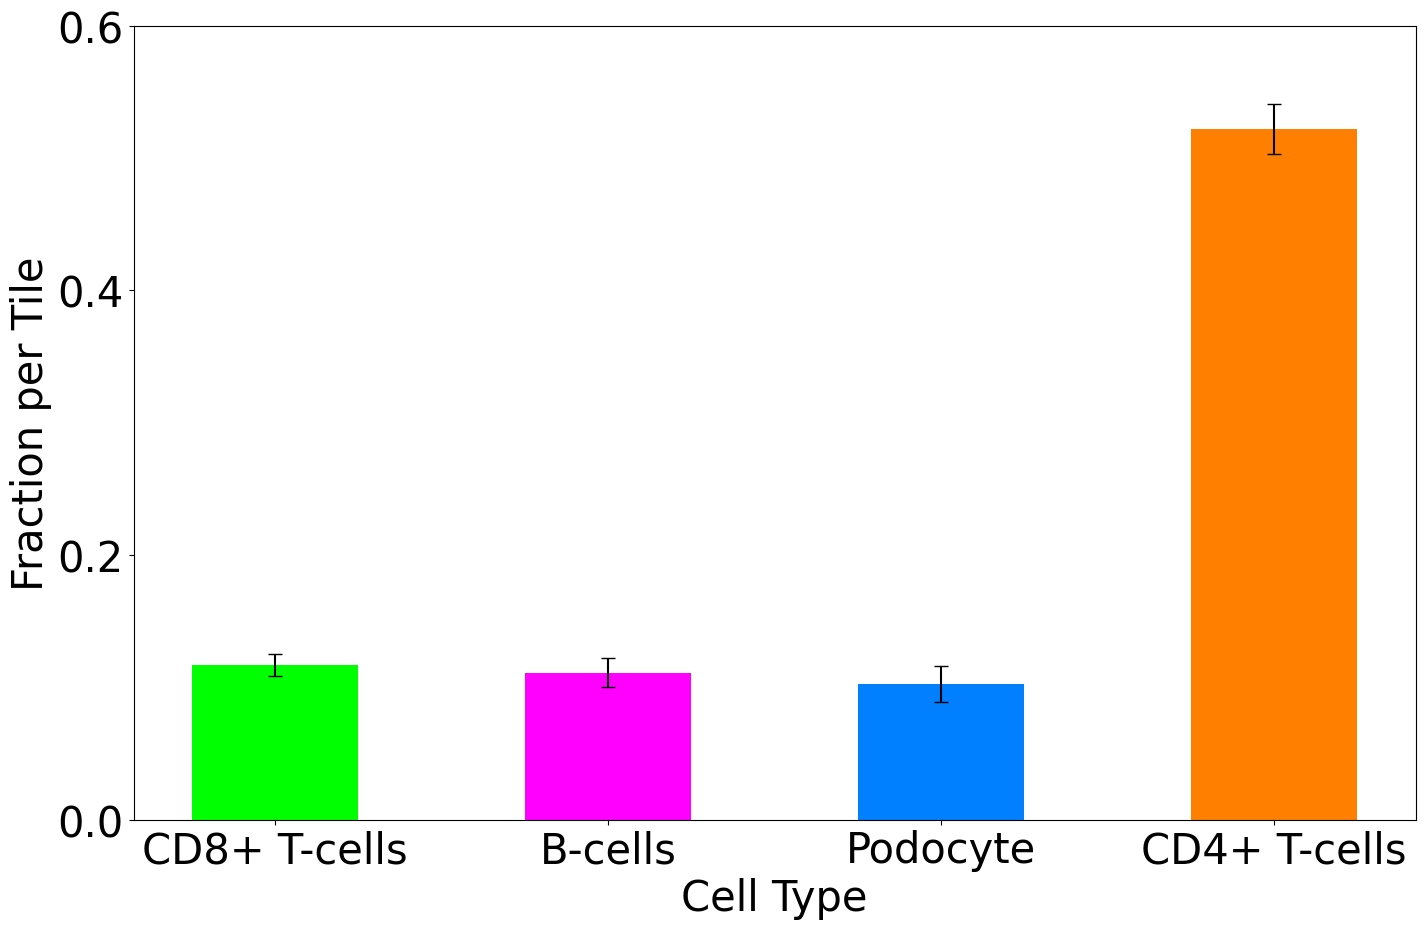

In [450]:
mpl.rcParams["font.size"] = 30
tile_size = 512
height, width = cell_segmentation_mask.shape

all_cell_types = list(cell_type_color_dict.keys())  
all_cell_types = [ct for ct in all_cell_types if ct != 'Unclassified']


cell_cluster_loc_df['tile_x'] = cell_cluster_loc_df['X'] // tile_size
cell_cluster_loc_df['tile_y'] = cell_cluster_loc_df['Y'] // tile_size

tile_cluster_counts = (
    cell_cluster_loc_df
    .groupby(['tile_y', 'tile_x', 'Cell Type'])
    .size()
    .reset_index(name='cell_type_count')
)

pivot = tile_cluster_counts.pivot_table(
    index=['tile_y', 'tile_x'],
    columns='Cell Type',
    values='cell_type_count',
    fill_value=0
)


pivot = pivot.reindex(
    columns=all_cell_types,
    fill_value=0
)


pivot_fraction = pivot.div(pivot.sum(axis=1), axis=0).fillna(0)


mean_per_cluster = pivot_fraction.mean(axis=0)
std_per_cluster = pivot_fraction.std(axis=0)
num_tiles = len(pivot_fraction)
stderr_per_cluster = std_per_cluster / np.sqrt(num_tiles)


colors = [cell_type_color_dict[c] for c in mean_per_cluster.index]


plt.figure(figsize=(15, 10))
ax = plt.gca()

ax.bar(
    mean_per_cluster.index,
    mean_per_cluster.values,
    yerr=stderr_per_cluster.values,
    capsize=5,
    color=colors,
    width=0.5
)

ax.set_xlabel('Cell Type')
ax.set_ylabel('Fraction per Tile')

yticks = ax.get_yticks()
ax.set_yticks(yticks[::2])

plt.tight_layout()
plt.show()


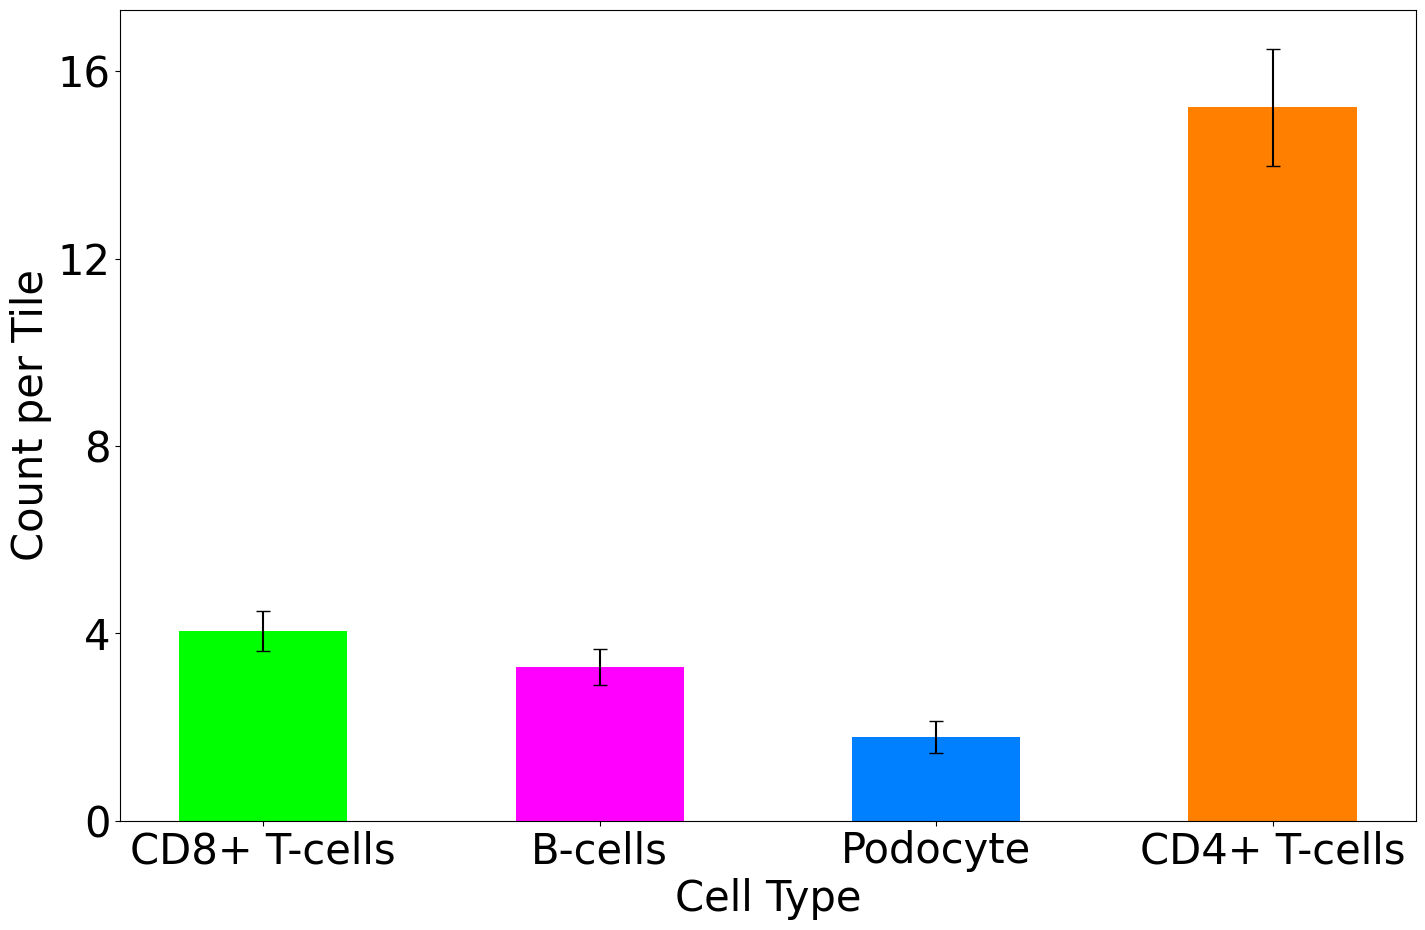

In [451]:
mpl.rcParams["font.size"] = 30
tile_size = 512
height, width = cell_segmentation_mask.shape

all_cell_types = list(cell_type_color_dict.keys())  
all_cell_types = [ct for ct in all_cell_types if ct != 'Unclassified']

cell_cluster_loc_df['tile_x'] = cell_cluster_loc_df['X'] // tile_size
cell_cluster_loc_df['tile_y'] = cell_cluster_loc_df['Y'] // tile_size

tile_cluster_counts = (
    cell_cluster_loc_df
    .groupby(['tile_y', 'tile_x', 'Cell Type'])
    .size()
    .reset_index(name='cell_type_count')
)

pivot = tile_cluster_counts.pivot_table(
    index=['tile_y', 'tile_x'],
    columns='Cell Type',
    values='cell_type_count',
    fill_value=0
)

pivot = pivot.reindex(
    columns=all_cell_types,
    fill_value=0
)

mean_per_cluster = pivot.mean(axis=0)
std_per_cluster = pivot.std(axis=0)
num_tiles = len(pivot)
stderr_per_cluster = std_per_cluster / np.sqrt(num_tiles)


colors = [cell_type_color_dict[c] for c in mean_per_cluster.index]

plt.figure(figsize=(15, 10))
ax = plt.gca()

ax.bar(
    mean_per_cluster.index,
    mean_per_cluster.values,
    yerr=stderr_per_cluster.values,
    capsize=5,
    color=colors,
    width=0.5
)

ax.set_xlabel('Cell Type')
ax.set_ylabel('Count per Tile')

yticks = ax.get_yticks()
ax.set_yticks(yticks[::2])

plt.tight_layout()
plt.show()


### Compare cell distribution for treated vs control

In [18]:
treated_key = '/Multiplex 2/ANCA 9'
control_key = '/Multiplex 2/CTRL 7'

In [19]:
treated_sample_name = treated_key.split('/')[-1]
control_sample_name = control_key.split('/')[-1]

In [20]:
treated_cell_clustering_base_path = 'Y:/coskun-lab/Aditi/01/Results/cell_segmentation_clustering' + treated_key + '/1x'
control_cell_clustering_base_path = 'Y:/coskun-lab/Aditi/01/Results/cell_segmentation_clustering' + control_key + '/1x'

In [21]:
treated_cell_cluster_loc_df = pd.read_csv(treated_cell_clustering_base_path + '/cell_cluster_location_merged_unclassified_within_contour.csv').drop(columns=['Unnamed: 0'])
with open(treated_cell_clustering_base_path + '/segmentation_mask_merged_within_contour_for_pixel_clustering.pickle', 'rb') as f: 
    treated_cell_segmentation_mask = pickle.load(f)
with open(treated_cell_clustering_base_path + '/cell_type_color_dict.pickle', 'rb') as f: 
    treated_cell_type_color_dict = pickle.load(f)

In [22]:
control_cell_cluster_loc_df = pd.read_csv(control_cell_clustering_base_path + '/cell_cluster_location_merged_unclassified_within_contour.csv').drop(columns=['Unnamed: 0'])
with open(control_cell_clustering_base_path + '/segmentation_mask_merged_within_contour_for_pixel_clustering.pickle', 'rb') as f: 
    control_cell_segmentation_mask = pickle.load(f)
with open(control_cell_clustering_base_path + '/cell_type_color_dict.pickle', 'rb') as f: 
    control_cell_type_color_dict = pickle.load(f)

In [23]:
treated_cell_types = list(treated_cell_type_color_dict.keys())
control_cell_types = list(control_cell_type_color_dict.keys())

In [24]:
from statannotations.Annotator import Annotator
import seaborn as sns 

C:\Users\akumar702\AppData\Local\Temp\ipykernel_370060\1847250361.py:98: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(common_cell_types, rotation=45, ha='right')


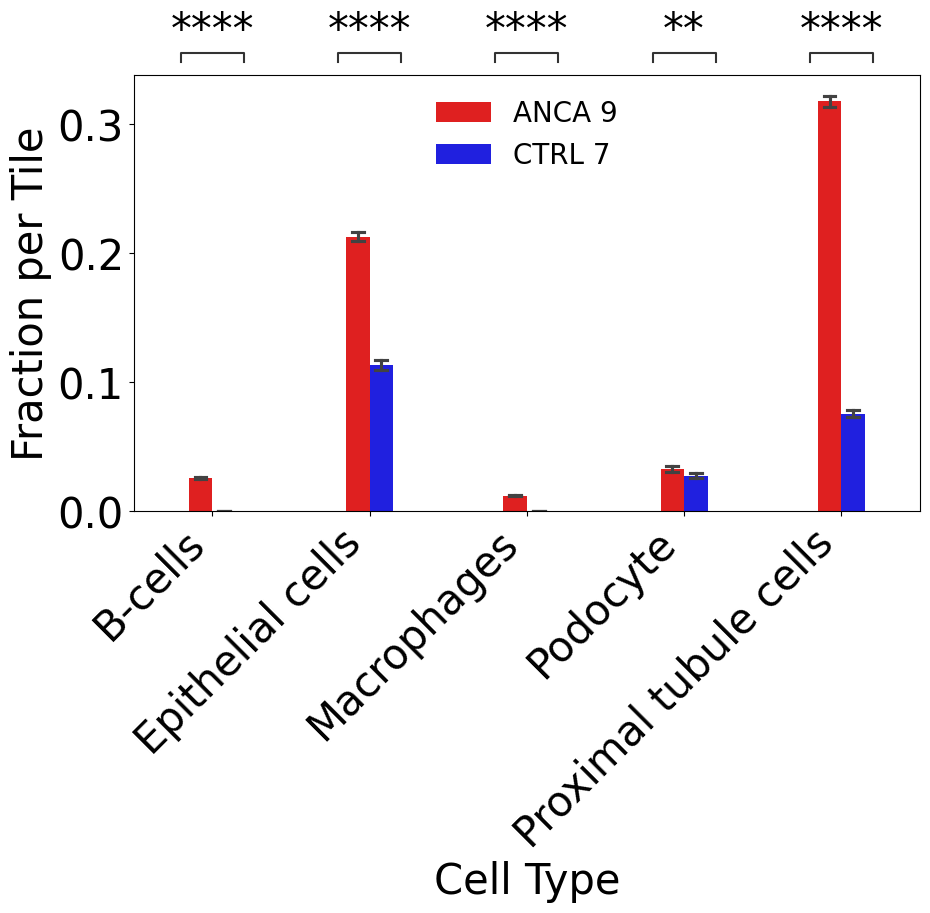

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statannotations.Annotator import Annotator

plt.rcParams["font.size"] = 30
tile_size = 512

def compute_tile_fractions(cell_cluster_loc_df, tile_size):


    df = cell_cluster_loc_df.copy()
    df['tile_x'] = df['X'] // tile_size
    df['tile_y'] = df['Y'] // tile_size

    tile_cluster_counts = (
        df
        .groupby(['tile_y', 'tile_x', 'Cell Type'])
        .size()
        .reset_index(name='cell_type_count')
    )

    pivot = tile_cluster_counts.pivot_table(
        index=['tile_y', 'tile_x'],
        columns='Cell Type',
        values='cell_type_count',
        fill_value=0
    )

    return pivot.div(pivot.sum(axis=1), axis=0)

pivot_frac_treated = compute_tile_fractions(
    treated_cell_cluster_loc_df, tile_size
)
pivot_frac_control = compute_tile_fractions(
    control_cell_cluster_loc_df, tile_size
)

common_cell_types = (
    set(treated_cell_types)
    & set(control_cell_types))
common_cell_types.discard('Unclassified')

common_cell_types = sorted([str(ct) for ct in common_cell_types])

pivot_frac_treated = pivot_frac_treated.reindex(
    columns=common_cell_types,
    fill_value=0
)
pivot_frac_control = pivot_frac_control.reindex(
    columns=common_cell_types,
    fill_value=0
)

pivot_frac_treated.columns = pivot_frac_treated.columns.astype(str)
pivot_frac_control.columns = pivot_frac_control.columns.astype(str)

pivot_frac_treated = pivot_frac_treated[common_cell_types]
pivot_frac_control = pivot_frac_control[common_cell_types]


df_long = pd.concat([
    pivot_frac_treated
        .reset_index(drop=True)
        .melt(var_name='Cell Type', value_name='Fraction')
        .assign(Sample=treated_sample_name),

    pivot_frac_control
        .reset_index(drop=True)
        .melt(var_name='Cell Type', value_name='Fraction')
        .assign(Sample=control_sample_name)
], ignore_index=True)


fig, ax = plt.subplots(figsize=(10, 10))

sns.barplot(
    data=df_long,
    x='Cell Type',
    y='Fraction',
    hue='Sample',
    order=common_cell_types,
    hue_order=[treated_sample_name, control_sample_name],
    estimator=np.mean,
    errorbar='se',   
    capsize=0.15,
    palette={
        treated_sample_name: 'red',
        control_sample_name: 'blue'
    },
    width=0.3,
    ax=ax
)

ax.set_ylabel('Fraction per Tile')
ax.set_xlabel('Cell Type')
ax.set_xticklabels(common_cell_types, rotation=45, ha='right')
ax.legend(frameon=False,
    loc='upper center', fontsize=20)

pairs = [
    ((ct, treated_sample_name), (ct, control_sample_name))
    for ct in common_cell_types
]

annotator = Annotator(
    ax,
    pairs,
    data=df_long,
    x='Cell Type',
    y='Fraction',
    hue='Sample',
    order=common_cell_types,
    hue_order=[treated_sample_name, control_sample_name]
)

annotator.configure(
    test='Mann-Whitney',
    text_format='star',
    loc='outside',
    comparisons_correction='BH',
    verbose=0
)

annotator.apply_and_annotate()

yticks = ax.get_yticks()
selected_yticks = yticks[::2]
ax.set_yticks(selected_yticks)

plt.tight_layout()
plt.show()


In [28]:
len(pivot_frac_treated)

1410

In [29]:
len(pivot_frac_control)

1181